# Chapter 10: Lasso Regression

In [11]:
%reset
%matplotlib inline
low_memory=False
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import seaborn as sns; sns.set()
from scipy import stats
import math
import os
import random
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Lasso
import warnings
warnings.filterwarnings('ignore')

## 10.1 Introduction & Motivation

We've learned a lot about building models for regression, classification, and clustering so far! But what if we could not only build great models but also take a closer look at the data itself and figure out which parts really matter? That’s where **Lasso Regression** comes in.

Lasso is more than just another regression model. It helps us uncover which features in our data are truly important by shrinking some coefficients to zero, effectively selecting the key players. Whether we’re predicting prices or classifying categories, Lasso cuts through the noise and keeps only what counts.

## 10.2 Problem Setting

Imagine you’re a wildlife detective, tasked with uncovering the hidden age of possums caught in the wild. With nothing but a handful of measurements—like head length, tail length, and skull size—you’re on a mission to crack the code of their age.

Why does this matter? Knowing a possum’s age can reveal fascinating stories about its life: how it grows, how long it survives, and what’s happening in its environment. By analyzing this data, you’ll uncover patterns that not only help us understand these curious creatures but also contribute to their conservation. 

The dataset contains 10 columns, where 'age' is the value you will try to predict.

- 'case': observation number
- 'site': The site number where the possum was trapped.
- 'Pop': Population, either Vic (Victoria) or other (New South Wales or Queensland).
- 'sex': Gender, either m (male) or f (female).
- 'age': Age.
- 'hdlngth': Head length, in mm.
- 'skullw': Skull width, in mm.
- 'totlngth': Total length, in cm.
- 'taill': Tail length, in cm.
- 'footlgth': foot length

## 10.3 Model

As always, we start by exploring the data.

In [12]:
rdf = pd.read_csv("Possum.csv")
rdf.head()

,case,site,Pop,sex,age,hdlngth,skullw,totlngth,taill,footlgth,earconch,eye,chest,belly
0,1,1,Vic,m,8.0,94.1,60.4,89.0,36.0,74.5,54.5,15.2,28.0,36.0
1,2,1,Vic,f,6.0,92.5,57.6,91.5,36.5,72.5,51.2,16.0,28.5,33.0
2,3,1,Vic,f,6.0,94.0,60.0,95.5,39.0,75.4,51.9,15.5,30.0,34.0
3,4,1,Vic,f,6.0,93.2,57.1,92.0,38.0,76.1,52.2,15.2,28.0,34.0
4,5,1,Vic,f,2.0,91.5,56.3,85.5,36.0,71.0,53.2,15.1,28.5,33.0


#### Question 1: Create a correlation matrix for the possum dataset. If you run into errors, solve them in a way we have seen before!

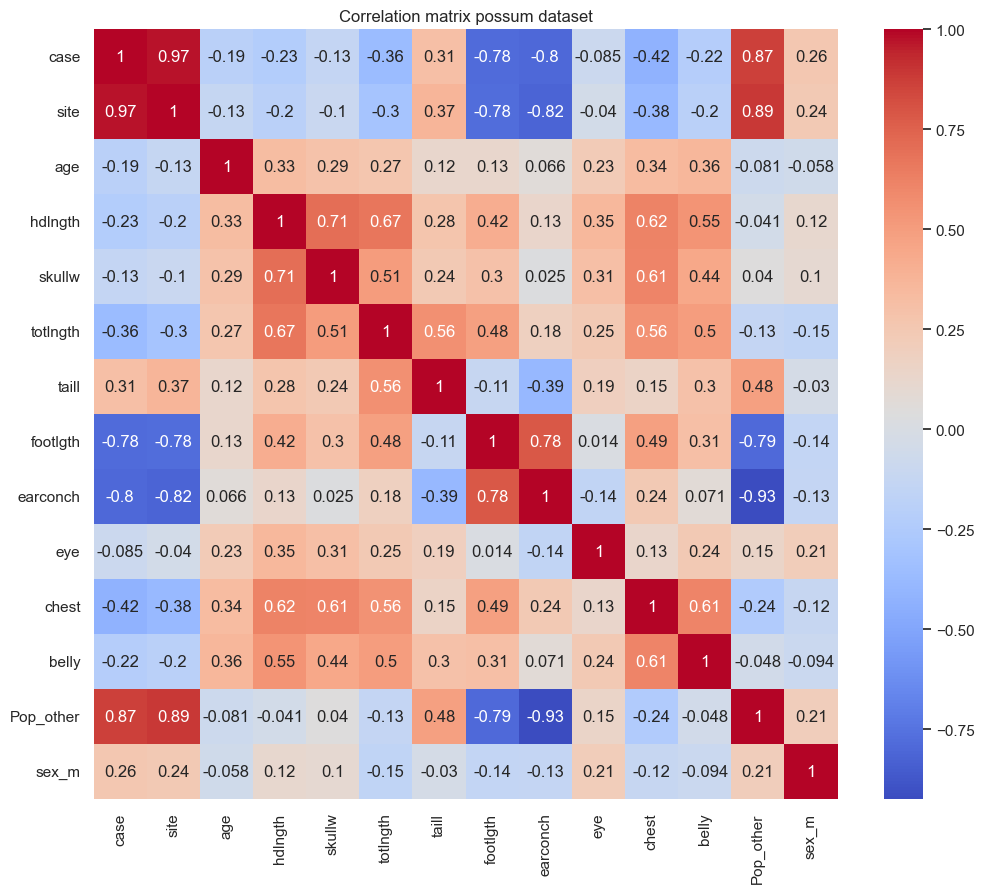

In [13]:
# A correlation matrix only works with numerical columns.
# Pop and sex are text columns, so we convert them to dummy variables.
df = rdf.dropna().copy()
df_numeric = pd.get_dummies(df, drop_first=True)

corr_matrix = df_numeric.corr(numeric_only=True)

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation matrix possum dataset")
plt.show()


#### Question 2: Looking at the correlation matrix, which features do you expect to contribute a lot to the 'age' variable? Which features contribute next to nothing?

In [14]:
age_correlations = corr_matrix["age"].drop("age").sort_values(key=abs, ascending=False)
print(age_correlations)

print("\nSterkste verbanden met age:")
print(age_correlations.head(5))

print("\nZwakste verbanden met age:")
print(age_correlations.tail(5))

print("\nConclusie:")
print("De hoogste absolute correlaties lijken het meest bij te dragen aan age.")
print("Features met een correlatie dicht bij 0 zullen waarschijnlijk weinig bijdragen.")


belly        0.360816
chest        0.335030
hdlngth      0.329505
skullw       0.285563
totlngth     0.268297
eye          0.231857
case        -0.192688
site        -0.127688
footlgth     0.126190
taill        0.120205
Pop_other   -0.080523
earconch     0.066234
sex_m       -0.057821
Name: age, dtype: float64

Sterkste verbanden met age:
belly       0.360816
chest       0.335030
hdlngth     0.329505
skullw      0.285563
totlngth    0.268297
Name: age, dtype: float64

Zwakste verbanden met age:
footlgth     0.126190
taill        0.120205
Pop_other   -0.080523
earconch     0.066234
sex_m       -0.057821
Name: age, dtype: float64

Conclusie:
De hoogste absolute correlaties lijken het meest bij te dragen aan age.
Features met een correlatie dicht bij 0 zullen waarschijnlijk weinig bijdragen.


#### Question 3: Train a polynomial regression model using all available features. Figure out the best degree to use. What's the MSE value you get?

In [15]:
# We gebruiken alle beschikbare features, behalve 'age' zelf en 'case' omdat dat enkel een ID is.
y = df_numeric["age"]
X = df_numeric.drop(["age", "case"], axis=1, errors="ignore")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

poly_results = []

for degree in range(1, 4):
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    y_pred = model.predict(X_test_poly)
    
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    poly_results.append({"degree": degree, "MSE": mse, "R2": r2})

poly_results_df = pd.DataFrame(poly_results)
print(poly_results_df)

best_degree = poly_results_df.loc[poly_results_df["MSE"].idxmin(), "degree"]
best_poly_mse = poly_results_df["MSE"].min()

print("\nBeste degree:", best_degree)
print("Beste MSE:", best_poly_mse)


   degree        MSE         R2
0       1   4.713182  -0.042384
1       2  70.595299 -14.613103
2       3  23.523562  -4.202553

Beste degree: 1
Beste MSE: 4.713181569510543


#### Question 4: Now train a lasso regression model. Use 0.1 as the value for alpha. What MSE do you get?

In [16]:
# Lasso werkt beter wanneer de features ongeveer op dezelfde schaal staan.
# We schalen manueel, zonder extra imports.
X_mean = X_train.mean()
X_std = X_train.std().replace(0, 1)

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

lasso = Lasso(alpha=0.1, max_iter=10000)
lasso.fit(X_train_scaled, y_train)

lasso_pred = lasso.predict(X_test_scaled)
lasso_mse = mean_squared_error(y_test, lasso_pred)
lasso_r2 = r2_score(y_test, lasso_pred)

print("Lasso MSE met alpha=0.1:", lasso_mse)
print("Lasso R2 met alpha=0.1:", lasso_r2)


Lasso MSE met alpha=0.1: 4.0568249705663355
Lasso R2 met alpha=0.1: 0.102778429277957


## 10.4 Model Evaluation

#### Question 5 Figure out a better value of alpha to use. First do so by plotting the effect of alpha on the current train-test split, then calculate an overal value using cross validation. Calculate the MSE for both 'best' values.

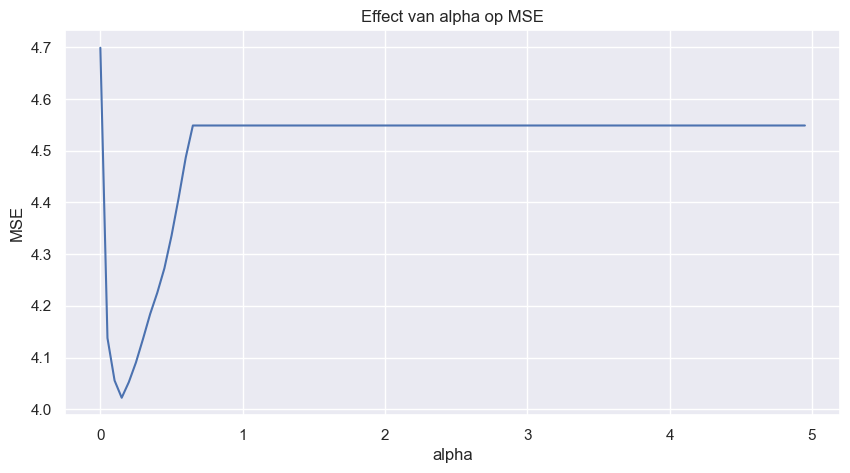

Beste alpha op deze train-test split: 0.15100000000000002
MSE met deze alpha: 4.02220575142289

Beste alpha via GridSearchCV: 0.8510000000000001
MSE met GridSearchCV-alpha: 4.54872767857143


In [17]:
# Methode 1: visueel zoeken op basis van dezelfde train-test split
alphas = np.arange(0.001, 5.001, 0.05)
alpha_results = []

for alpha in alphas:
    model = Lasso(alpha=alpha, max_iter=10000)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    alpha_results.append({
        "alpha": alpha,
        "MSE": mean_squared_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    })

alpha_results_df = pd.DataFrame(alpha_results)

plt.figure(figsize=(10, 5))
plt.plot(alpha_results_df["alpha"], alpha_results_df["MSE"])
plt.xlabel("alpha")
plt.ylabel("MSE")
plt.title("Effect van alpha op MSE")
plt.show()

best_visual = alpha_results_df.loc[alpha_results_df["MSE"].idxmin()]
print("Beste alpha op deze train-test split:", best_visual["alpha"])
print("MSE met deze alpha:", best_visual["MSE"])

# Methode 2: GridSearchCV
param_grid = {"alpha": np.arange(0.001, 5.001, 0.05)}
grid = GridSearchCV(
    Lasso(max_iter=10000),
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)
grid.fit(X_train_scaled, y_train)

best_cv_alpha = grid.best_params_["alpha"]
best_cv_model = grid.best_estimator_
best_cv_pred = best_cv_model.predict(X_test_scaled)
best_cv_mse = mean_squared_error(y_test, best_cv_pred)

print("\nBeste alpha via GridSearchCV:", best_cv_alpha)
print("MSE met GridSearchCV-alpha:", best_cv_mse)


## 10.5 Exercises

#### Question 1: See section 10.3
#### Question 2: See section 10.3
#### Question 3: See section 10.3
#### Question 4: See section 10.3
#### Question 5: See section 10.4
#### Question 6: Lasso regression can also be used for feature selecting. You can do so by looking at which collumns have been assigned which coefficient. Look at your 'best' trained model (using GSCV) and show the coefficients of each feature and which are dropped in your model. Look back at the features you identified in question 2, how good/bad was your prediction?

In [18]:
coef_table = pd.DataFrame({
    "feature": X.columns,
    "coefficient": best_cv_model.coef_
})
coef_table["absolute_coefficient"] = coef_table["coefficient"].abs()
coef_table = coef_table.sort_values("absolute_coefficient", ascending=False)

print(coef_table)

selected_features = coef_table[coef_table["coefficient"] != 0]["feature"].tolist()
dropped_features = coef_table[coef_table["coefficient"] == 0]["feature"].tolist()

print("\nGeselecteerde features:")
print(selected_features)

print("\nGedropte features:")
print(dropped_features)

print("\nVergelijking met vraag 2:")
print("Features met hoge absolute correlatie met age worden meestal sneller behouden.")
print("Toch kan Lasso anders kiezen, omdat Lasso naar alle features samen kijkt en niet enkel naar losse correlaties.")


      feature  coefficient  absolute_coefficient
0        site          0.0                   0.0
1     hdlngth          0.0                   0.0
2      skullw          0.0                   0.0
3    totlngth          0.0                   0.0
4       taill          0.0                   0.0
5    footlgth          0.0                   0.0
6    earconch          0.0                   0.0
7         eye          0.0                   0.0
8       chest          0.0                   0.0
9       belly          0.0                   0.0
10  Pop_other          0.0                   0.0
11      sex_m          0.0                   0.0

Geselecteerde features:
[]

Gedropte features:
['site', 'hdlngth', 'skullw', 'totlngth', 'taill', 'footlgth', 'earconch', 'eye', 'chest', 'belly', 'Pop_other', 'sex_m']

Vergelijking met vraag 2:
Features met hoge absolute correlatie met age worden meestal sneller behouden.
Toch kan Lasso anders kiezen, omdat Lasso naar alle features samen kijkt en niet enkel 

#### Question 7: Lasso regression isn't only useful when working with regression problems. Let's have a look at the feature selection properties of lasso regression in classification. Load in the 'Diabetes' dataset from the logistic regression chapter, create a logistic regression model and calculate the accuracy.

In [19]:
# Alleen met de toegelaten imports: daarom maken we een kleine logistic-regression functie met numpy.
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def train_logistic_regression(X_train_np, y_train_np, learning_rate=0.05, epochs=5000):
    weights = np.zeros(X_train_np.shape[1])
    bias = 0
    
    for epoch in range(epochs):
        linear_output = np.dot(X_train_np, weights) + bias
        predictions = sigmoid(linear_output)
        
        error = predictions - y_train_np
        weights = weights - learning_rate * np.dot(X_train_np.T, error) / len(y_train_np)
        bias = bias - learning_rate * np.mean(error)
        
    return weights, bias

def predict_logistic_regression(X_np, weights, bias):
    probabilities = sigmoid(np.dot(X_np, weights) + bias)
    return (probabilities >= 0.5).astype(int)

# Dataset inladen. De code werkt zodra Diabetes.csv in dezelfde map staat.
if os.path.exists("Diabetes.csv"):
    diabetes = pd.read_csv("Diabetes.csv")
elif os.path.exists("diabetes.csv"):
    diabetes = pd.read_csv("diabetes.csv")
else:
    diabetes = None
    print("Diabetes.csv werd niet gevonden. Plaats Diabetes.csv in dezelfde map en run deze cel opnieuw.")

if diabetes is not None:
    diabetes = diabetes.dropna().copy()
    
    possible_targets = ["Outcome", "outcome", "diabetes", "Diabetes", "class", "Class", "target", "Target"]
    target_column = None
    for column in possible_targets:
        if column in diabetes.columns:
            target_column = column
            break
    
    if target_column is None:
        target_column = diabetes.columns[-1]
        print("Geen standaard targetnaam gevonden. Laatste kolom gebruikt als target:", target_column)
    
    y_diabetes = diabetes[target_column]
    X_diabetes = diabetes.drop(target_column, axis=1)
    X_diabetes = pd.get_dummies(X_diabetes, drop_first=True)
    
    X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
        X_diabetes, y_diabetes, test_size=0.2, random_state=42
    )
    
    d_mean = X_train_d.mean()
    d_std = X_train_d.std().replace(0, 1)
    X_train_d_scaled = (X_train_d - d_mean) / d_std
    X_test_d_scaled = (X_test_d - d_mean) / d_std
    
    weights, bias = train_logistic_regression(
        X_train_d_scaled.values,
        y_train_d.values,
        learning_rate=0.05,
        epochs=5000
    )
    
    diabetes_pred = predict_logistic_regression(X_test_d_scaled.values, weights, bias)
    base_accuracy = np.mean(diabetes_pred == y_test_d.values)
    
    print("Accuracy met alle features:", base_accuracy)


Accuracy met alle features: 0.7532467532467533


#### Question 8: Now that we have a standard to compare to, use lasso regression on the dataset to select only the valuable features. Drop them from the dataset and create a new model. Has your accuracy imporved?

In [20]:
if diabetes is not None:
    # Lasso gebruiken voor feature selection op de diabetes dataset.
    # Coëfficiënten die 0 worden, beschouwen we als minder waardevol.
    lasso_selector = Lasso(alpha=0.01, max_iter=10000)
    lasso_selector.fit(X_train_d_scaled, y_train_d)
    
    diabetes_coef_table = pd.DataFrame({
        "feature": X_diabetes.columns,
        "coefficient": lasso_selector.coef_
    })
    diabetes_coef_table["absolute_coefficient"] = diabetes_coef_table["coefficient"].abs()
    diabetes_coef_table = diabetes_coef_table.sort_values("absolute_coefficient", ascending=False)
    
    print(diabetes_coef_table)
    
    selected_diabetes_features = diabetes_coef_table[
        diabetes_coef_table["coefficient"] != 0
    ]["feature"].tolist()
    
    # Veiligheid: als alpha te streng is en niets selecteert, nemen we de drie sterkste features.
    if len(selected_diabetes_features) == 0:
        selected_diabetes_features = diabetes_coef_table.head(3)["feature"].tolist()
    
    print("\nGeselecteerde diabetes features:")
    print(selected_diabetes_features)
    
    X_train_selected = X_train_d_scaled[selected_diabetes_features]
    X_test_selected = X_test_d_scaled[selected_diabetes_features]
    
    weights_selected, bias_selected = train_logistic_regression(
        X_train_selected.values,
        y_train_d.values,
        learning_rate=0.05,
        epochs=5000
    )
    
    diabetes_pred_selected = predict_logistic_regression(
        X_test_selected.values,
        weights_selected,
        bias_selected
    )
    selected_accuracy = np.mean(diabetes_pred_selected == y_test_d.values)
    
    print("\nAccuracy met alle features:", base_accuracy)
    print("Accuracy na Lasso feature selection:", selected_accuracy)
    
    if selected_accuracy > base_accuracy:
        print("De accuracy is verbeterd.")
    elif selected_accuracy < base_accuracy:
        print("De accuracy is niet verbeterd.")
    else:
        print("De accuracy is gelijk gebleven.")


                    feature  coefficient  absolute_coefficient
1                   Glucose     0.167795              0.167795
5                       BMI     0.105344              0.105344
7                       Age     0.066579              0.066579
0               Pregnancies     0.028776              0.028776
6  DiabetesPedigreeFunction     0.028338              0.028338
2             BloodPressure    -0.024431              0.024431
4                   Insulin    -0.013085              0.013085
3             SkinThickness     0.000000              0.000000

Geselecteerde diabetes features:
['Glucose', 'BMI', 'Age', 'Pregnancies', 'DiabetesPedigreeFunction', 'BloodPressure', 'Insulin']

Accuracy met alle features: 0.7532467532467533
Accuracy na Lasso feature selection: 0.7467532467532467
De accuracy is niet verbeterd.
